# Supplementary Figure S2d. Power of TransMap-local and alternative trans-QTL tests at intermediate SNR

Power at nominal α = 0.05 of single-gene trans-eQTL testing (trans-eGene), Eigengene, TransPCO and TransMap-local at intermediate per-gene signal-to-noise ratio (s = 0.004), varying the causal trans-gene proportion (n = 1,000, M = 20), sample size (M = 20, 50% causal) and module size M (n = 1,000, 50% causal), with residual correlation ρ = 0.1/0.3/0.5 (columns) and homogeneous or heterogeneous effect signs (rows). Power is the mean, over 1,000 simulated datasets, of the within-dataset fraction of tested variants rejected; error bars are the original simulation 95% confidence intervals (replicate-cluster intervals from the simulation summary).

Data note: the author's input table (`supplementary_figure.tsv`) displayed synthetic, lowered Eigengene values for 19 settings (flagged `is_mocked`, labelled "ILLUSTRATIVE shifted source interval; NOT a statistical 95% CI"). This notebook plots only the original simulation estimates kept in that table; the 19 affected rows are flagged by `altered_in_author_figure`.

Input: `data/Figure_S2d_power_midSNR.rds`.

In [1]:
library(ggplot2)
library(patchwork)
pw <- readRDS("data/Figure_S2d_power_midSNR.rds")
head(pw)
table(pw$panel, pw$method)
pw[pw$altered_in_author_figure, c("panel", "axis_value", "rho", "sign_mode", "method", "power")]

,panel,axis_value,n,M,m,causal_fraction,rho,sign_mode,per_gene_snr,alpha,n_replicates,method,power,ci_lower,ci_upper,altered_in_author_figure,effect
,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<lgl>,<fct>
1,causal_fraction,25,1000,20,5,0.25,0.1,positive,0.004,0.05,1000,Eigengene,0.8208333,0.7988160,0.8428506,TRUE,Homogeneous
2,causal_fraction,25,1000,20,5,0.25,0.1,positive,0.004,0.05,1000,TransPCO,0.5485000,0.5186667,0.5783333,FALSE,Homogeneous
3,causal_fraction,25,1000,20,5,0.25,0.1,positive,0.004,0.05,1000,TransMap-local,0.7173333,0.6908192,0.7438475,FALSE,Homogeneous
4,causal_fraction,25,1000,20,5,0.25,0.1,positive,0.004,0.05,1000,trans-eGene,0.4806667,0.4507935,0.5105399,FALSE,Homogeneous
5,causal_fraction,50,1000,20,10,0.50,0.1,positive,0.004,0.05,1000,Eigengene,0.9331667,0.9205944,0.9457389,TRUE,Homogeneous
6,causal_fraction,50,1000,20,10,0.50,0.1,positive,0.004,0.05,1000,TransPCO,0.8481667,0.8273860,0.8689473,FALSE,Homogeneous


                 
                  trans-eGene Eigengene TransPCO TransMap-local
  causal_fraction          24        24       24             24
  module_size              18        18       18             18
  sample_size              24        24       24             24

,panel,axis_value,rho,sign_mode,method,power
,<chr>,<int>,<dbl>,<chr>,<fct>,<dbl>
1,causal_fraction,25,0.1,positive,Eigengene,0.8208333
5,causal_fraction,50,0.1,positive,Eigengene,0.9331667
9,sample_size,1000,0.1,positive,Eigengene,0.9331667
13,module_size,20,0.1,positive,Eigengene,0.9331667
25,sample_size,400,0.1,positive,Eigengene,0.6973333
29,sample_size,600,0.1,positive,Eigengene,0.8348333
33,sample_size,800,0.1,positive,Eigengene,0.8935000
65,causal_fraction,100,0.3,positive,Eigengene,0.9440000
69,sample_size,400,0.3,positive,Eigengene,0.5683333


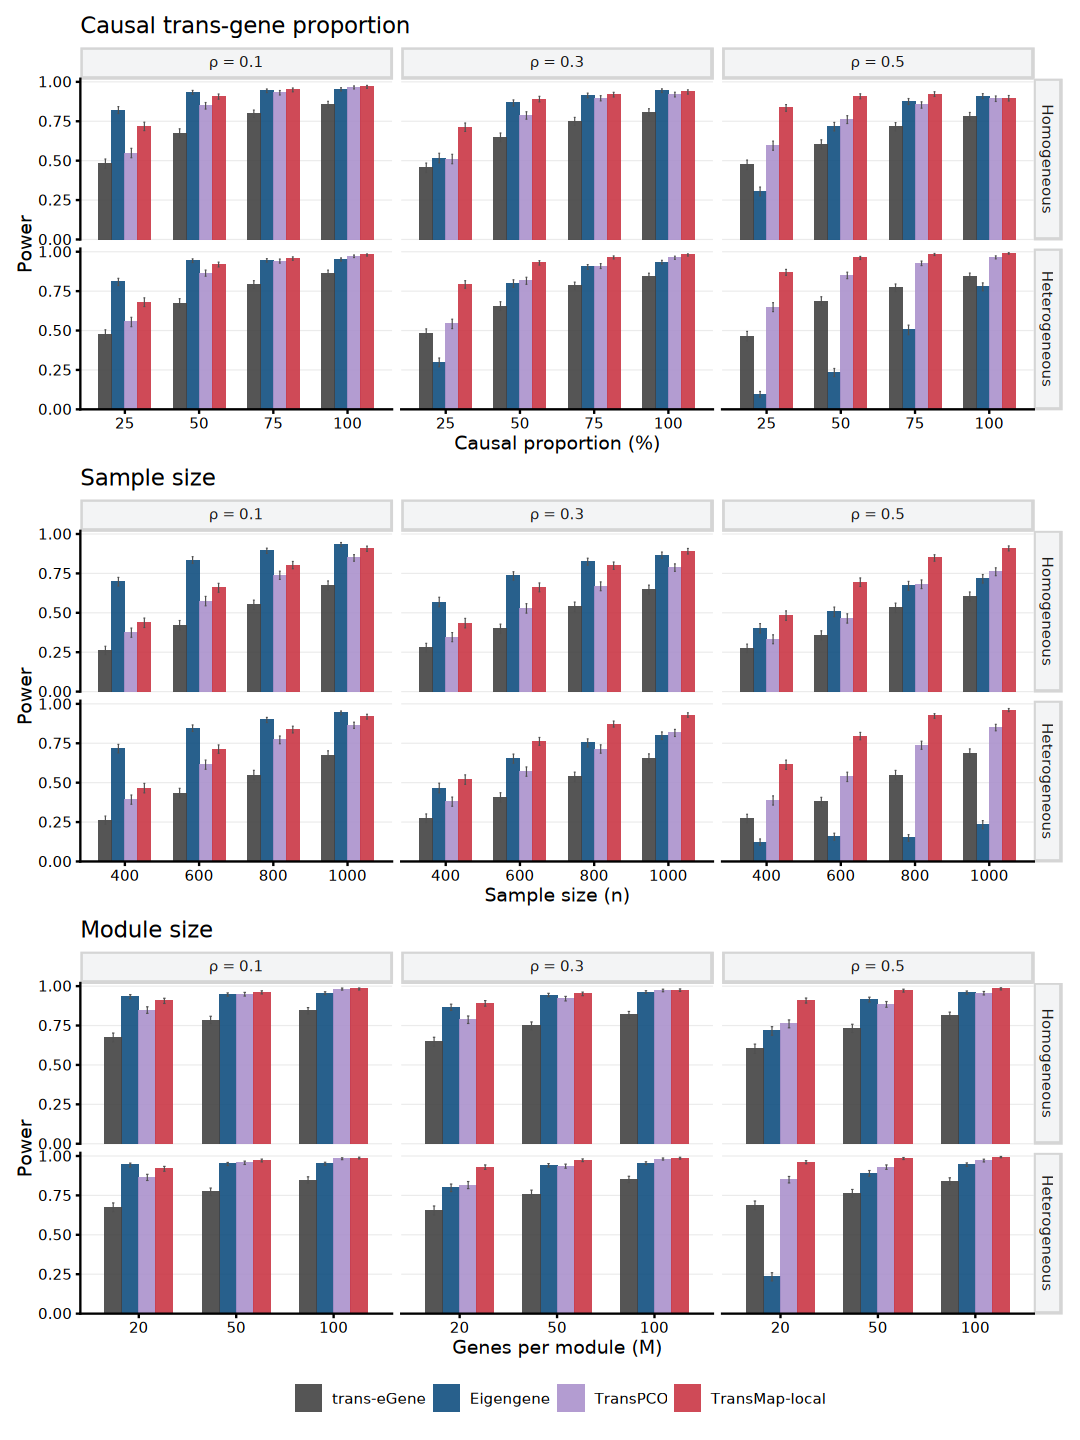

In [2]:
method_colors <- c("trans-eGene" = "#434343", "Eigengene" = "#114F80",
                   "TransPCO" = "#AB91CC", "TransMap-local" = "#CA3745")
pw$rho_label <- factor(sprintf("rho == %.1f", pw$rho), levels = c("rho == 0.1", "rho == 0.3", "rho == 0.5"))

make_block <- function(panel_name, x_values, title, x_title) {
  z <- pw[pw$panel == panel_name, ]
  z$x_label <- factor(as.character(z$axis_value), levels = as.character(x_values))
  dodge <- position_dodge(width = 0.7)
  ggplot(z, aes(x = x_label, y = power, fill = method, group = method)) +
    geom_col(position = dodge, width = 0.7, alpha = 0.9) +
    geom_errorbar(aes(ymin = ci_lower, ymax = ci_upper), position = dodge,
                  width = 0.1, linewidth = 0.25, colour = "#505050") +
    facet_grid(effect ~ rho_label, labeller = labeller(rho_label = label_parsed)) +
    scale_fill_manual(values = method_colors, drop = FALSE, name = NULL) +
    scale_y_continuous(breaks = seq(0, 1, 0.25), limits = c(0, 1.02), expand = expansion(mult = 0)) +
    labs(title = title, x = x_title, y = "Power") +
    theme_classic(base_size = 11) +
    theme(strip.background = element_rect(fill = "#F3F4F5", colour = "#D5D5D5"),
          panel.grid.major.y = element_line(colour = "#EBEBEB", linewidth = 0.25),
          legend.position = "bottom")
}

p <- wrap_plots(
  make_block("causal_fraction", c(25, 50, 75, 100), "Causal trans-gene proportion", "Causal proportion (%)"),
  make_block("sample_size", c(400, 600, 800, 1000), "Sample size", "Sample size (n)"),
  make_block("module_size", c(20, 50, 100), "Module size", "Genes per module (M)"),
  ncol = 1, guides = "collect") & theme(legend.position = "bottom")

options(repr.plot.width = 9, repr.plot.height = 12)
p